# 1. Text exploration — MulTaBench core text

Audit the **20 official core TEXT datasets** before any Jev call. Focus on text-column counts, lengths, missing inputs, exact duplicates and the amount of reusable extraction. All source versions and text-column lists are pinned in `config/0. exploration/datasets.yaml`.

## 1. Scope and provenance

The public CSVs and metadata are loaded at pinned versions. Missing data can be downloaded when `allow_download: true`; existing data are hash-checked. No model code or weights are loaded. See `docs/DATA_SOURCES.md` for the official text definition and audit denominators. Each notebook runs independently.


In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local, display_json
from src.utils.provenance import provenance
from src.data.audit import audit_collection
from src.visualize import figures, style
style.apply()
cfg = load_config()
from src.data.audit import audit_summary
from src.visualize.audit import burden_figures
from src.visualize.exploration import OVERVIEW_LABELS, dataset_overview, overview_figures, text_column_figures, reuse_figure
import matplotlib.pyplot as plt

NOTEBOOK = "0. exploration/01_data_exploration"
from src.utils.notebook_report import begin_report, report_section, finish_report
begin_report()
report_section('1. Scope and provenance')
save = figures.FigureSaver(NOTEBOOK)
config_hash = save_resolved_config(cfg, NOTEBOOK)
display_json("Execution provenance", provenance())
audit = audit_collection(cfg)

from src.data.long_text import long_text_audit
from src.visualize.long_text import long_text_figures


Audit: Fake Job Postings


Audit: Jigsaw Toxicity


Audit: Kickstarter


Audit: Data Scientist Salary


Audit: Michelin Guide


...

Audit: Rotten Tomatoes


Audit: SciMagojr Impact

Audit: Vancouver Salaries

Audit: Video Games Sales


Audit: Zomato Restaurants


## 2. Dataset overview

One row per dataset. Feature counts exclude the target. Binary versus multiclass is determined from the official classification task and observed distinct class vocabulary; numerical targets are not automatically treated as regression. Class vocabulary may be inspected below; no frequencies enter request metadata.


The overview is ordered by **task and dataset size → text availability → distinct texts and per-column reuse → text length → joint availability and reuse → total extraction workload**. It includes total text cells and the empty percentage; unique texts counted within each column; missingness and reuse in both absolute counts and percentages. Means exclude empty text cells. Joint p95 and maximum lengths reveal long-input problems. Redundant total-column counts are omitted: text and non-text column counts already give the predictor dimensions. The overview is split into two figures at final A4 print width; the table retains the full set of measurements. The same complete overview is saved as `overview.csv`.

Dataset,Experiment status,Task,Classes,Rows,Text columns,Non-text columns,All text cells,Empty text cells (%),Distinct texts (within columns),Distinct / nonempty texts (%),Mean tokens / nonempty text,Rows without text (%),Distinct joint texts,Joint avoided (%),Joint tokens median,Joint tokens p95,Joint tokens maximum,Unique requests (both modes),Requests avoided (both modes),"Avoided (both modes, %)"
Fake Job Postings,Included,binary_classification,2.0,12725,3,2,38175,27.76,21958,79.62,148.23,0.00,12674,0.40,272.0,734.00,3736,34631,5671,14.07
Jigsaw Toxicity,Included,binary_classification,2.0,100000,1,30,100000,0.00,99661,99.66,74.72,0.00,99661,0.34,51.0,239.00,384,99661,100337,50.17
Kickstarter,Included,binary_classification,2.0,86502,3,6,259506,0.00,258820,99.74,18.97,0.00,86502,0.00,49.0,120.00,568,345321,680,0.20
Data Scientist Salary,Included,multiclass_classification,6.0,15841,5,1,79205,4.43,30594,40.42,11.05,0.00,12074,23.78,55.0,66.00,85,42668,48869,53.39
Michelin Guide,Included,multiclass_classification,5.0,18843,6,5,113058,0.99,63756,56.95,29.93,0.00,18843,0.00,168.0,271.00,427,82599,48186,36.84
Product Sentiment,Included,multiclass_classification,4.0,5091,1,1,5091,0.00,5084,99.86,26.50,0.00,5084,0.14,27.0,36.00,45,5084,5098,50.07
Spotify Genres,REMOVED,multiclass_classification,114.0,114000,3,15,342000,0.00,151634,44.34,4.92,0.00,89379,21.60,12.0,27.00,250,241013,214983,47.15
US Accidents,Included,multiclass_classification,4.0,100001,6,38,600006,0.08,170390,28.42,4.84,0.00,96585,3.42,26.0,42.00,139,266975,432549,61.83
Wine Review,Included,multiclass_classification,30.0,84123,2,3,168246,0.02,79356,47.18,32.00,0.00,78995,6.10,62.0,93.00,210,158319,94017,37.26
Women's Clothing,Included,multiclass_classification,5.0,18788,2,8,37576,9.93,29605,87.47,43.96,3.54,18119,0.02,78.0,133.00,139,45326,6642,12.78


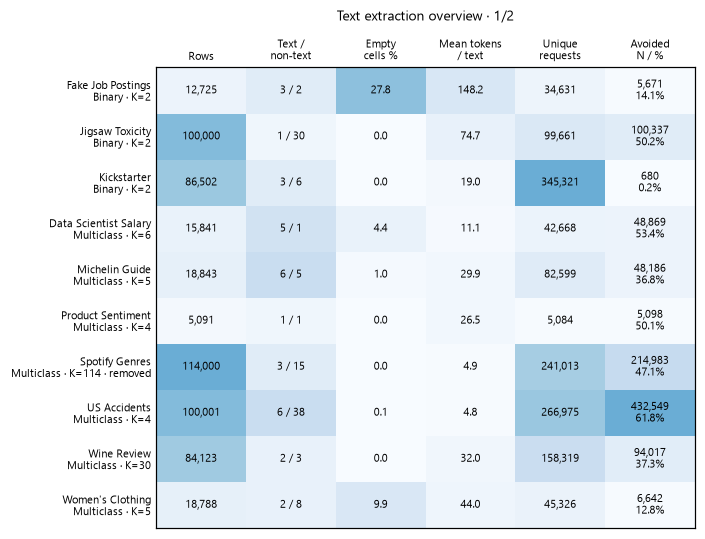

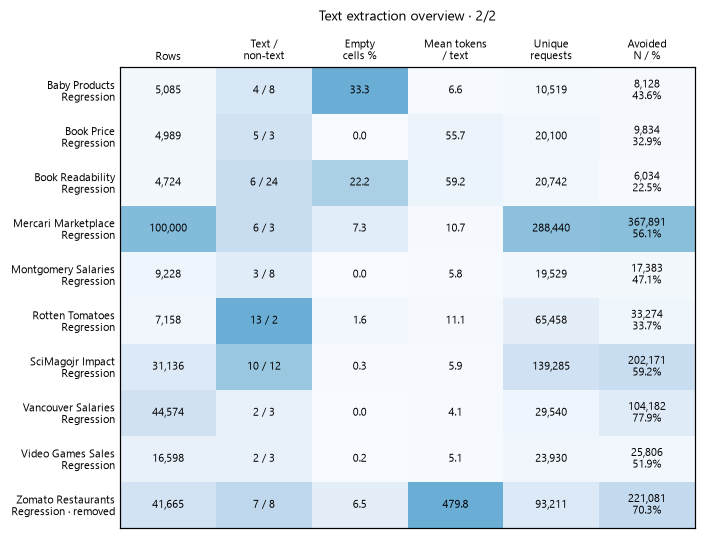

In [2]:
report_section('2. Dataset overview')
overview = dataset_overview(audit)
display_local(overview.rename(columns=OVERVIEW_LABELS).round(2))
overview.to_csv(audit.folder / "overview.csv", index=False)
for fig, name, caption in overview_figures(overview, cfg["token_estimation"]["characters_per_token"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
for dataset_id in audit.summary.dataset_id:
    display_json(audit.metadata(dataset_id).dataset_name + " — task metadata", audit.details[dataset_id]["task_metadata"])


## 3. Individual text columns: length, missingness and repetition

One row per official text column. `nonempty_characters_mean` excludes null/whitespace-only inputs; the existing character/token statistics include them as zero. `unique_nonempty_inputs` counts the exact inputs that need a first response for this field. `repeated_nonempty_rows` counts the additional copies that can reuse it; `top_input_frequencies` lists the frequencies of the most common inputs without exposing their text.

Equality is exact: nonempty whitespace, capitalization, value type, and column names matter. Null, nonfinite and whitespace-only inputs share the agreed missing policy. The detailed audit below retains descriptive dtype/target statistics separately.


dataset_id,feature,nonempty_characters_mean,characters_median,characters_p95,tokens_mean,tokens_p95,missing_pct,missing_or_empty_pct,nonempty_rows,unique_nonempty_inputs,unique_nonempty_ratio,repeated_nonempty_rows,top_input_frequencies
BIN_TEXT_FAKE_JOB_POSTING,title,28.315992,26.0,57.0,7.452338,15.0,0.000000,0.000000,12725,9240,0.726130,3485,"[107, 62, 57, 53, 51]"
BIN_TEXT_FAKE_JOB_POSTING,salary_range,10.380460,0.0,11.0,0.485658,3.0,83.269155,83.269155,2129,755,0.354627,1374,"[110, 44, 36, 26, 25]"
BIN_TEXT_FAKE_JOB_POSTING,description,1251.867956,1058.0,2910.6,313.291081,728.0,0.007859,0.015717,12723,11963,0.940266,760,"[25, 18, 18, 17, 16]"
BIN_TEXT_JIGSAW_TOXICITY,comment_text,297.383234,202.0,953.0,74.718090,239.0,0.001000,0.001000,99999,99661,0.996620,338,"[16, 9, 8, 8, 7]"
BIN_TEXT_KICKSTARTER_FUNDING,name,53.673414,37.0,289.0,13.797404,73.0,0.001156,0.001156,86501,86313,0.997827,188,"[5, 4, 4, 3, 3]"
BIN_TEXT_KICKSTARTER_FUNDING,desc,136.033898,128.0,372.0,34.392800,93.0,0.006936,0.006936,86496,86005,0.994323,491,"[14, 8, 7, 7, 6]"
BIN_TEXT_KICKSTARTER_FUNDING,keywords,33.661592,33.0,52.0,8.729671,13.0,0.000000,0.000000,86502,86502,1.000000,0,"[1, 1, 1, 1, 1]"
MUL_TEXT_DATA_SCIENTIST_SALARY,experience,7.430781,7.0,9.0,2.101824,3.0,0.000000,0.000000,15841,128,0.008080,15713,"[1010, 964, 750, 665, 545]"
MUL_TEXT_DATA_SCIENTIST_SALARY,job_description,100.855753,102.0,108.0,19.893757,27.0,22.145067,22.145067,12333,7859,0.637233,4474,"[117, 39, 26, 26, 25]"
MUL_TEXT_DATA_SCIENTIST_SALARY,job_desig,39.172906,38.0,69.0,10.173221,18.0,0.000000,0.000000,15841,10097,0.637397,5744,"[108, 64, 50, 45, 45]"


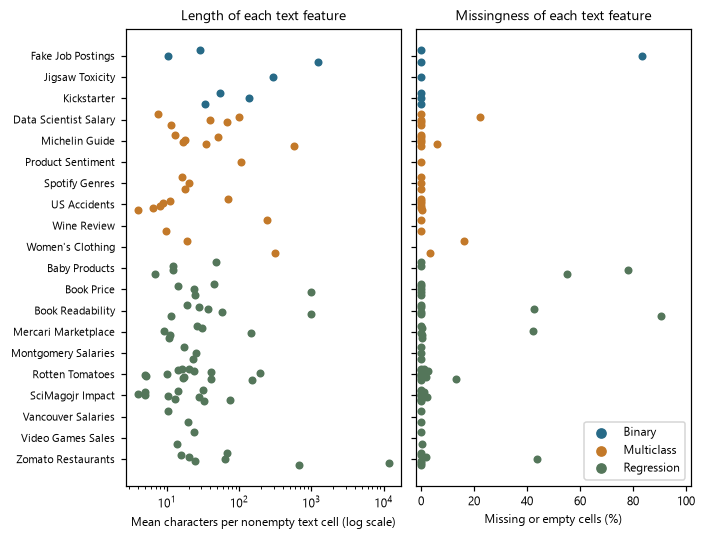

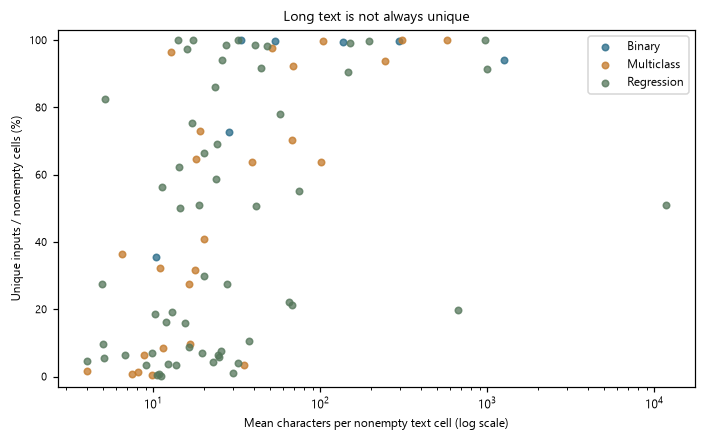

In [3]:
report_section('3. Individual text columns: length, missingness and repetition')
display_local(audit.text[["dataset_id", "feature", "nonempty_characters_mean", "characters_median", "characters_p95", "tokens_mean", "tokens_p95", "missing_pct", "missing_or_empty_pct", "nonempty_rows", "unique_nonempty_inputs", "unique_nonempty_ratio", "repeated_nonempty_rows", "top_input_frequencies"]])

for fig, name, caption in text_column_figures(audit):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 4. Joint duplicates and total reusable extraction

Joint equality compares **all named available text fields together**, omitting missing fields. Count this directly; do not assume every joint row is unique. `joint_single_field_unique_overlap` counts joint inputs that equal a per-column input because only one field is available.

`combined_unique_inputs = per_column_unique_inputs + joint_unique_inputs - joint_single_field_unique_overlap`.

These are exact counts for fixed task metadata, question, model and configuration. They describe requests to obtain and cache once, not the number of numeric feature columns. Identical complete requests reuse the first saved response. We have not tested whether repeating a paid call returns exactly the same probabilities; cache reuse does not require this guarantee. No target values enter the matching.


dataset,rows,text_columns,per_column_nonempty_inputs,per_column_unique_inputs,per_column_reuse_savings_pct,joint_nonempty_inputs,joint_unique_inputs,joint_unique_ratio,joint_reuse_savings_pct,joint_missing_or_empty_pct,joint_single_field_unique_overlap,combined_unique_inputs
Fake Job Postings,12725,3,27577,21958,20.375675,12725,12674,0.995992,0.400786,0.000000,1,34631
Jigsaw Toxicity,100000,1,99999,99661,0.338003,99999,99661,0.996620,0.338003,0.001000,99661,99661
Kickstarter,86502,3,259499,258820,0.261658,86502,86502,1.000000,0.000000,0.000000,1,345321
Data Scientist Salary,15841,5,75696,30594,59.583069,15841,12074,0.762199,23.780064,0.000000,0,42668
Michelin Guide,18843,6,111942,63756,43.045506,18843,18843,1.000000,0.000000,0.000000,0,82599
Product Sentiment,5091,1,5091,5084,0.137498,5091,5084,0.998625,0.137498,0.000000,5084,5084
Spotify Genres,114000,3,341997,151634,55.662184,113999,89379,0.784033,21.596681,0.000877,0,241013
US Accidents,100001,6,599523,170390,71.579072,100001,96585,0.965840,3.415966,0.000000,0,266975
Wine Review,84123,2,168213,79356,52.824098,84123,78995,0.939042,6.095836,0.000000,32,158319
Women's Clothing,18788,2,33846,29605,12.530284,18122,18119,0.999834,0.016554,3.544816,2398,45326


,dataset_id,mode,text_columns,rows,nonempty_rows,missing_or_empty_rows,missing_or_empty_pct,unique_nonempty_inputs,unique_nonempty_ratio,repeated_nonempty_rows,reuse_savings_pct,repeated_distinct_inputs,rows_in_repeated_groups,most_common_input_count,top_input_frequencies
3,BIN_TEXT_FAKE_JOB_POSTING,joint,"[title, salary_range, description]",12725,12725,0,0.000000,12674,0.995992,51,0.400786,49,100,3,"[3, 3, 2, 2, 2]"
5,BIN_TEXT_JIGSAW_TOXICITY,joint,[comment_text],100000,99999,1,0.001000,99661,0.996620,338,0.338003,202,540,16,"[16, 9, 8, 8, 7]"
9,BIN_TEXT_KICKSTARTER_FUNDING,joint,"[name, desc, keywords]",86502,86502,0,0.000000,86502,1.000000,0,0.000000,0,0,1,"[1, 1, 1, 1, 1]"
15,MUL_TEXT_DATA_SCIENTIST_SALARY,joint,"[experience, job_description, job_desig, key_s...",15841,15841,0,0.000000,12074,0.762199,3767,23.780064,3061,6828,10,"[10, 9, 8, 8, 8]"
22,MUL_TEXT_MICHELIN_RESTAURANTS,joint,"[Name, Address, Location, Cuisine, FacilitiesA...",18843,18843,0,0.000000,18843,1.000000,0,0.000000,0,0,1,"[1, 1, 1, 1, 1]"
24,MUL_TEXT_PRODUCT_SENTIMENT,joint,[Product_Description],5091,5091,0,0.000000,5084,0.998625,7,0.137498,7,14,2,"[2, 2, 2, 2, 2]"
28,MUL_TEXT_SPOTIFY_GENRES,joint,"[artists, album_name, track_name]",114000,113999,1,0.000877,89379,0.784033,24620,21.596681,16795,41415,12,"[12, 10, 9, 9, 9]"
35,MUL_TEXT_US_ACCIDENTS,joint,"[Description, Street, City, County, Zipcode, A...",100001,100001,0,0.000000,96585,0.965840,3416,3.415966,2857,6273,10,"[10, 9, 8, 6, 6]"
38,MUL_TEXT_WINE_REVIEW,joint,"[description, province]",84123,84123,0,0.000000,78995,0.939042,5128,6.095836,5126,10254,3,"[3, 3, 2, 2, 2]"
41,MUL_TEXT_WOMEN_CLOTHING_REVIEW,joint,"[Title, Review Text]",18788,18122,666,3.544816,18119,0.999834,3,0.016554,2,5,3,"[3, 2, 1, 1, 1]"


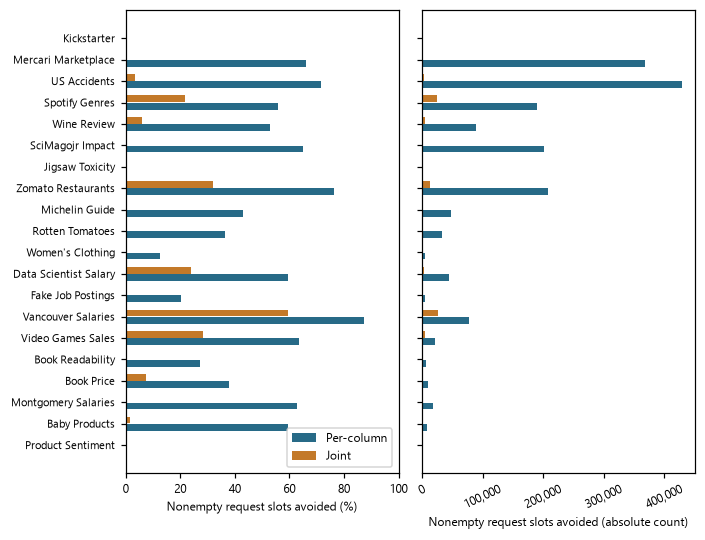

In [4]:
report_section('4. Joint duplicates and total reusable extraction')
display_local(audit.summary[["dataset", "rows", "text_columns", "per_column_nonempty_inputs", "per_column_unique_inputs", "per_column_reuse_savings_pct", "joint_nonempty_inputs", "joint_unique_inputs", "joint_unique_ratio", "joint_reuse_savings_pct", "joint_missing_or_empty_pct", "joint_single_field_unique_overlap", "combined_unique_inputs"]])
display_local(audit.reuse[audit.reuse["mode"] == "joint"])
fig, name, caption = reuse_figure(audit.summary)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)


## 5. Full column and target audit

Expand a dataset to see **every feature**, missingness, unique counts/ratios, numeric statistics, categorical cardinalities/common values, text-length statistics and representative examples. Unique ratios use nonmissing rows as denominator. Character/word/token length statistics include missing text as empty, matching workload accounting. “Words” means whitespace-separated strings.

Tokens are approximated as `ceil(characters / 4)`, not measured with Jev’s tokenizer. Examples are unique nonempty values at deterministic length ranks near 10%, 50% and 90%, clipped only for display. Full request text is never clipped.

The target distribution or regression quantiles are **audit-only**. The request builder has no input for these statistics. “Other” includes date-like columns. Non-text feature classification uses the CSV dtype; no model preprocessing has been selected.

In [5]:
report_section('5. Full column and target audit')
for dataset_id in audit.summary.dataset_id:
    detail = audit.details[dataset_id]
    display_json(audit.metadata(dataset_id).dataset_name + " — full column audit", {
        "features": audit.columns[audit.columns.dataset_id == dataset_id].to_dict(orient="records"),
        "text_statistics": audit.text[audit.text.dataset_id == dataset_id].to_dict(orient="records"),
        "numeric_statistics": audit.numeric[audit.numeric.dataset_id == dataset_id].fillna("missing").to_dict(orient="records"),
        "categorical_statistics": audit.categorical[audit.categorical.dataset_id == dataset_id].to_dict(orient="records"),
        "text_examples": detail["text_examples"],
        "target_audit_only": detail["target_audit_only"],
        "issues": detail["issues"],
    })


## 6. Text burden

Combined row tokens use `ceil(sum(text characters) / 4)`. Notebook 2 adds metadata, question wording, class choices and JSON escaping. No non-text features enter Jev. Short strings and names count as text under the official annotation.


dataset,text_columns,combined_tokens_mean,combined_tokens_median,combined_tokens_p95,combined_tokens_max,total_text_tokens
Fake Job Postings,3,320.803929,272.0,734.00,3736,4082230
Jigsaw Toxicity,1,74.718090,51.0,239.00,384,7471809
Kickstarter,3,56.216330,49.0,120.00,568,4862825
Data Scientist Salary,5,51.428066,55.0,66.00,85,814672
Michelin Guide,6,176.004617,168.0,271.00,427,3316455
Product Sentiment,1,26.497545,27.0,36.00,45,134899
Spotify Genres,3,13.983816,12.0,27.00,250,1594155
US Accidents,6,27.203458,26.0,42.00,139,2720373
Wine Review,2,63.624788,62.0,93.00,210,5352308
Women's Clothing,2,78.935438,78.0,133.00,139,1483039


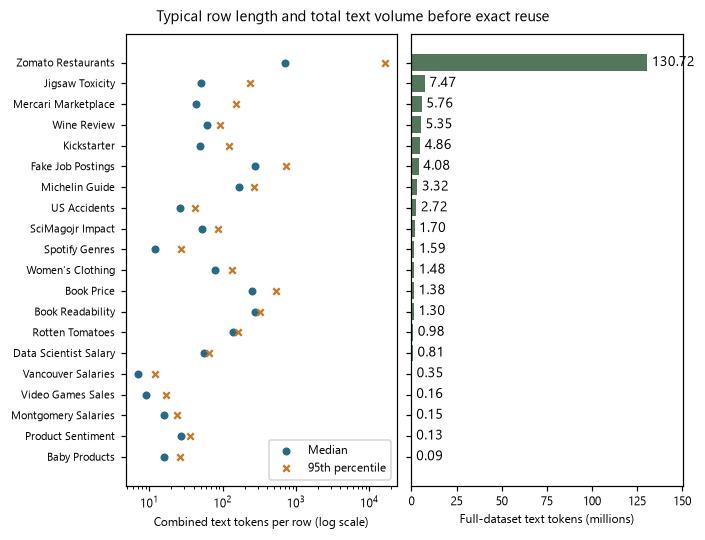

In [6]:
report_section('6. Text burden')
display_local(audit.summary[["dataset", "text_columns", "combined_tokens_mean", "combined_tokens_median", "combined_tokens_p95", "combined_tokens_max", "total_text_tokens"]])
for fig, name, caption in burden_figures(audit.summary, cfg["token_estimation"]["characters_per_token"]):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 7. Long text: p99, maxima and longest-cell examples

Both tables exclude missing/empty inputs from length quantiles. The dataset table compares **individual text cells** with **joint row text**; the column table covers every text column. p99 means 99% of observed lengths are at or below this value. The maximum can be much larger.

Boxplots use p01/p99 whiskers and show maxima separately. The 32,000-token line is only a **text-length screen**: actual request limits also include JSON escaping, task metadata and the question. Notebook 2 checks the complete intended payload approximately. No text is shortened for extraction here and no paid call is made.

Each dataset's longest cell is shown below using beginning/middle/end excerpts. Full original text is saved in the ignored audit cache and linked in each example. Clipping is only for readable display; ties use the first CSV row. Percentiles, maxima and exceedance counts include duplicates, since they describe dataset rows rather than unique paid requests.


dataset,text_columns,cell_characters_p99,cell_characters_max,cell_tokens_p99,cell_tokens_max,joint_characters_p99,joint_characters_max,joint_tokens_p99,joint_tokens_max,cells_above_text_only_screen,joint_rows_above_text_only_screen,longest_text_column,longest_row_id
Fake Job Postings,3,3631.24,14907,908.00,3727,4333.04,14941,1083.76,3736,0,0,description,csv:11703
Jigsaw Toxicity,1,999.00,1535,250.00,384,999.00,1535,250.00,384,0,0,comment_text,csv:66157
Kickstarter,3,387.00,1270,97.00,318,734.00,2272,184.00,568,0,0,desc,csv:7416
Data Scientist Salary,5,108.00,109,27.00,28,276.00,339,69.00,85,0,0,job_description,csv:48
Michelin Guide,6,916.00,1550,229.00,388,1283.00,1705,321.00,427,0,0,Description,csv:16105
Product Sentiment,1,152.00,178,38.00,45,152.00,178,38.00,45,0,0,Product_Description,csv:4022
Spotify Genres,3,67.00,513,17.00,129,157.00,1000,40.00,250,0,0,artists,csv:98961
US Accidents,6,123.00,523,31.00,131,204.00,556,51.00,139,0,0,Description,csv:99404
Wine Review,2,401.00,829,101.00,208,439.00,839,110.00,210,0,0,description,csv:34425
Women's Clothing,2,502.00,508,126.00,127,543.00,556,136.00,139,0,0,Review Text,csv:14084


dataset,text_column,nonempty_cells,characters_mean,characters_p95,characters_p99,characters_max,tokens_p95,tokens_p99,tokens_max,cells_above_text_only_screen,longest_row_id
Fake Job Postings,title,12725,28.32,57.00,73.00,142,15.00,19.00,36,0,csv:576
Fake Job Postings,salary_range,2129,10.38,13.00,13.00,20,4.00,4.00,5,0,csv:7325
Fake Job Postings,description,12723,1251.87,2910.80,4309.58,14907,728.00,1077.56,3727,0,csv:11703
Jigsaw Toxicity,comment_text,99999,297.38,953.00,999.00,1535,239.00,250.00,384,0,csv:66157
Kickstarter,name,86501,53.67,289.00,314.00,1072,73.00,79.00,268,0,csv:73240
Kickstarter,desc,86496,136.03,372.00,391.00,1270,93.00,98.00,318,0,csv:7416
Kickstarter,keywords,86502,33.66,52.00,52.00,117,13.00,13.00,30,0,csv:57107
Data Scientist Salary,experience,15841,7.43,9.00,9.00,9,3.00,3.00,3,0,csv:13
Data Scientist Salary,job_description,12333,100.86,108.00,109.00,109,27.00,28.00,28,0,csv:48
Data Scientist Salary,job_desig,15841,39.17,69.00,70.00,70,18.00,18.00,18,0,csv:44


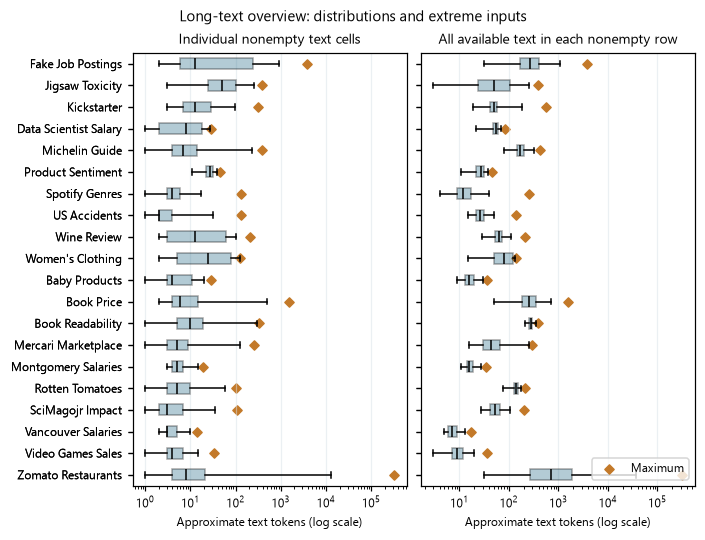

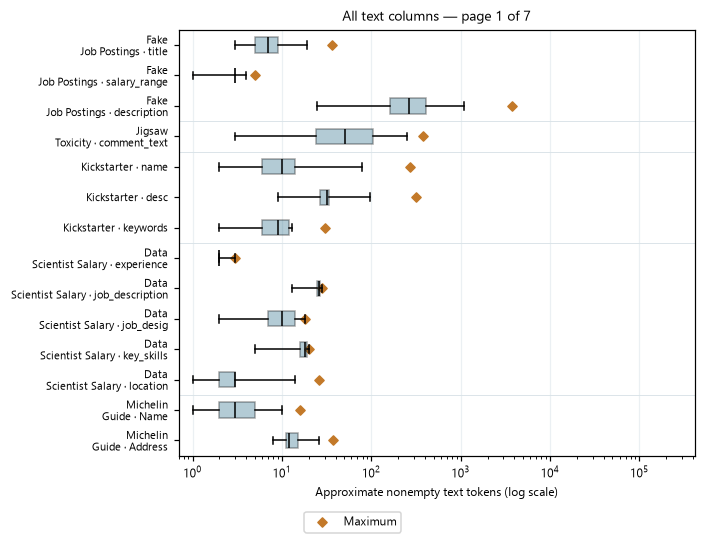

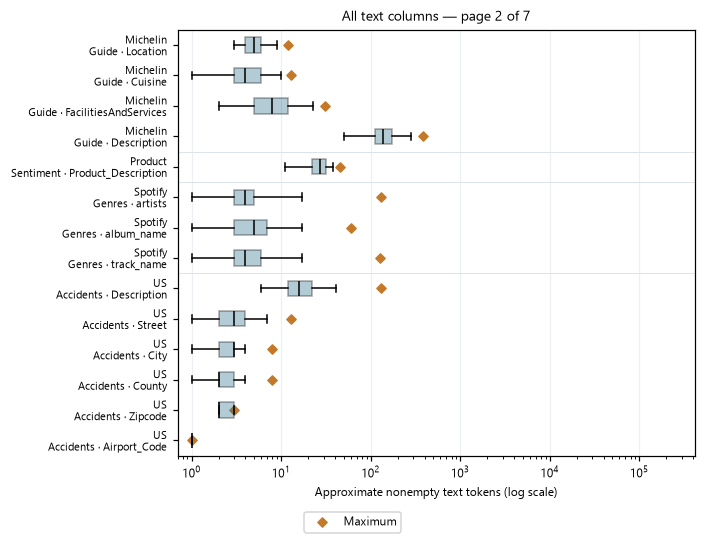

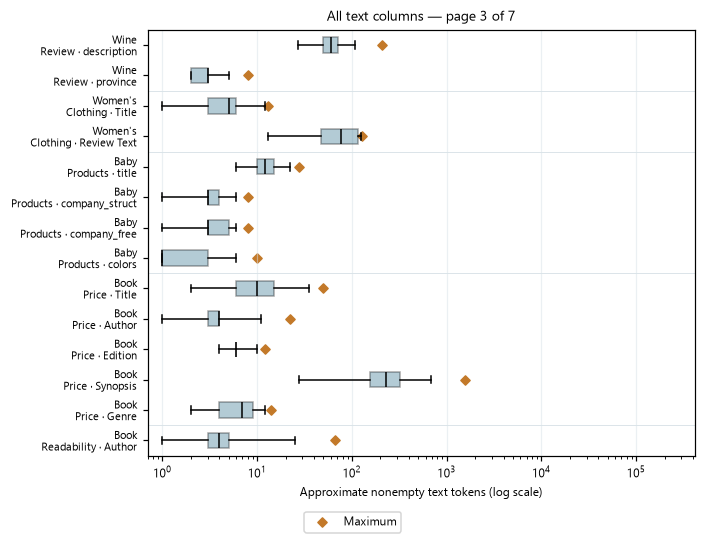

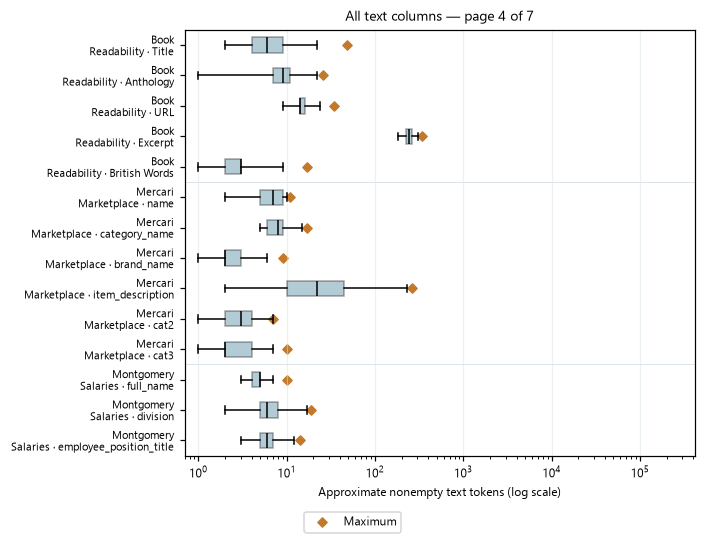

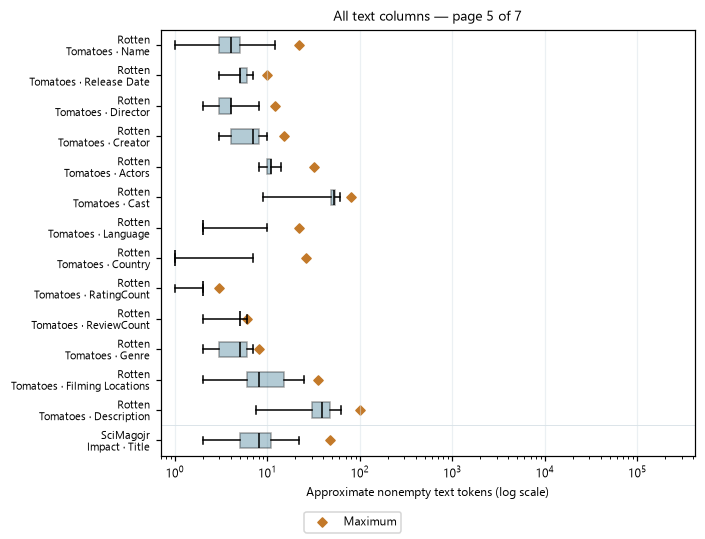

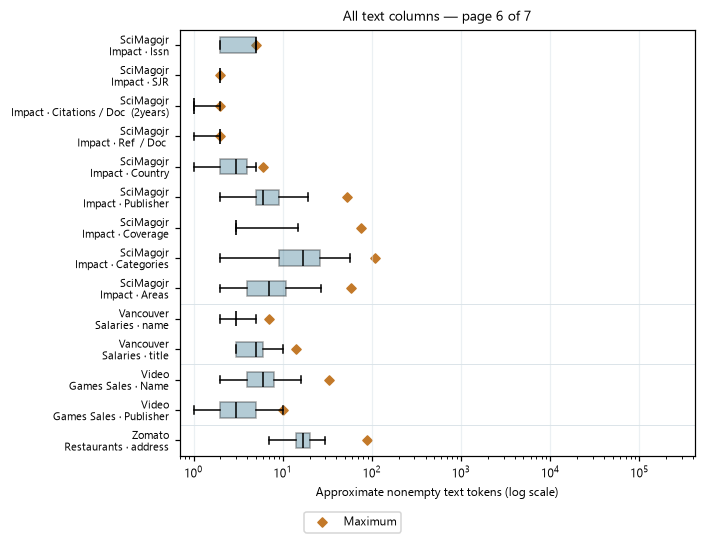

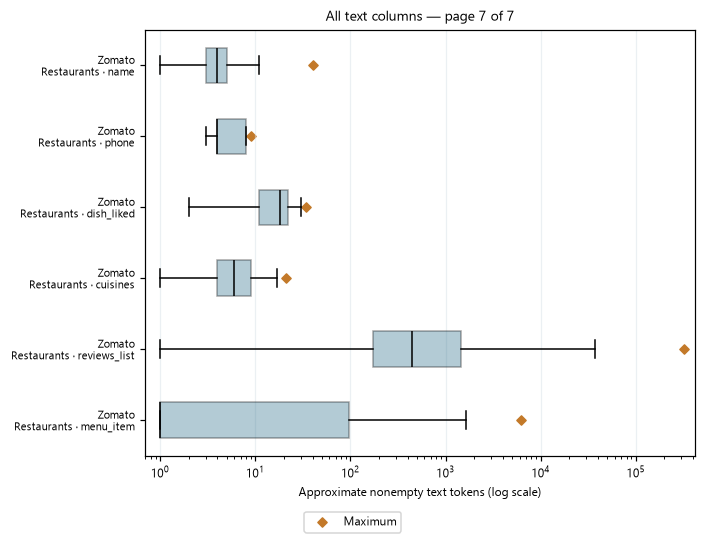

In [7]:
report_section('7. Long text: p99, maxima and longest cells')
long_datasets, long_columns, longest_examples = long_text_audit(audit, cfg)
display_local(long_datasets[["dataset", "text_columns", "cell_characters_p99", "cell_characters_max", "cell_tokens_p99", "cell_tokens_max", "joint_characters_p99", "joint_characters_max", "joint_tokens_p99", "joint_tokens_max", "cells_above_text_only_screen", "joint_rows_above_text_only_screen", "longest_text_column", "longest_row_id"]].round(2))
display_local(long_columns[["dataset", "text_column", "nonempty_cells", "characters_mean", "characters_p95", "characters_p99", "characters_max", "tokens_p95", "tokens_p99", "tokens_max", "cells_above_text_only_screen", "longest_row_id"]].round(2))
for fig, name, caption in long_text_figures(long_datasets, long_columns):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
for example in longest_examples:
    display_json(example["dataset"] + " — longest text cell", example)


## 8. How many numeric text features will each dataset add?

For **T text columns** and **K classes**, multiclass extraction adds **T × K** per-column probabilities, **K** joint probabilities, or **(T + 1) × K** combined probabilities. For a dataset with one text column, the separate and joint request are identical, so the combined matrix retains one block. Binary classification and regression add one main numeric feature per input group. All nine regression probabilities remain stored for a later distribution ablation.

These are **feature columns, not API calls**: one request returns all class probabilities. Duplicate text reduces extraction calls but does not reduce the feature-table width or number of dataset rows. Missing inputs occupy the same columns with missing values. K probabilities sum to one and contain at most K−1 independent dimensions; the agreed representation retains all K.

The table retains all 20 datasets and marks the two removals. Float64 MiB is the size of a hypothetical dense array of added main features, excluding row IDs, original features, responses, confidence and storage overhead/compression. It is not a SQLite file-size prediction.

dataset,status,task,rows,text_columns,non_text_columns,classes,features_per_text_input,per_column_features,joint_features,combined_features,predictor_columns_with_combined,combined_numeric_values,combined_float64_mib
Fake Job Postings,Included,binary_classification,12725,3,2,2.0,1,3,1,4,6,50900,0.39
Kickstarter,Included,binary_classification,86502,3,6,2.0,1,3,1,4,10,346008,2.64
Jigsaw Toxicity,Included,binary_classification,100000,1,30,2.0,1,1,1,1,31,100000,0.76
Spotify Genres,REMOVED,multiclass_classification,114000,3,15,114.0,114,342,114,456,471,51984000,396.61
Wine Review,Included,multiclass_classification,84123,2,3,30.0,30,60,30,90,93,7571070,57.76
Data Scientist Salary,Included,multiclass_classification,15841,5,1,6.0,6,30,6,36,37,570276,4.35
Michelin Guide,Included,multiclass_classification,18843,6,5,5.0,5,30,5,35,40,659505,5.03
US Accidents,Included,multiclass_classification,100001,6,38,4.0,4,24,4,28,66,2800028,21.36
Women's Clothing,Included,multiclass_classification,18788,2,8,5.0,5,10,5,15,23,281820,2.15
Product Sentiment,Included,multiclass_classification,5091,1,1,4.0,4,4,4,4,5,20364,0.16


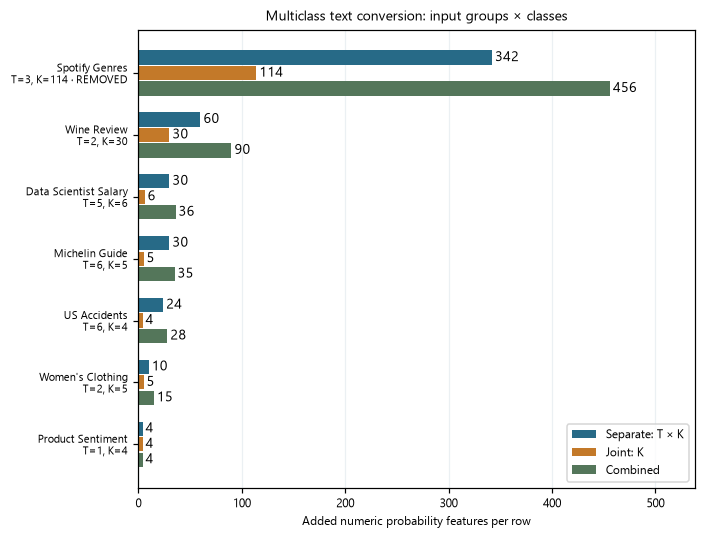

In [8]:
report_section('8. Numeric feature counts and multiclass expansion')
from src.jev.dimensions import numeric_feature_dimensions
from src.visualize.dimensions import multiclass_dimensions_figure
feature_dimensions = numeric_feature_dimensions(audit, excluded=load_config('feature_creation')['dataset_selection']['exclude'])
display_local(feature_dimensions.drop(columns=['dataset_id']).round(2))
fig, name, caption = multiclass_dimensions_figure(feature_dimensions)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)


## 9. Saved outputs

CSV/JSON audits and encoded length arrays use a run-scoped temporary directory and are deleted when the run finishes. The notebook, figures and full printed report retain the inspected results. Resolved notebook configurations are stored under output_JEVPFN/manifests/notebooks/. Figures are in `output_JEVPFN/figures/0. exploration/01_data_exploration/`, with `Captions.md`. The full final summary contains every displayed audit detail and plotted value, including local examples. Generated reports are gitignored. The runner saves executed cell outputs into these notebooks for local inspection; do not publish raw examples without reviewing them.


In [9]:
report_section('9. Saved outputs')
display_json("Permanent outputs", {"figures": str(save.folder), "report": "output_JEVPFN/All Results.md", "captions": "output_JEVPFN/figures/Captions.md", "config_sha256": config_hash, "audit_intermediates": "Temporary; discarded after the run. All measured tables are preserved in this notebook and its full report."})

## Summary

Section order matches the notebook. The notebook saves this complete text verbatim into `output_JEVPFN/All Results.md`.

In [10]:
finish_report(NOTEBOOK, audit_summary(audit) + "\n" + save.summary())


0. exploration/01_data_exploration

1. Scope and provenance


Execution provenance
{
  "code_sha256": "397d024a50ed4690d4f77ec31b5a94b248a9b58e3328db4dfe791c5ba7bfb7de",
  "git_head": "58097f11c27b1afe93633c539366194d017838b2",
  "git_dirty": true,
  "tfm_library_pin": "5f1b3f8f1611681579aba052a86c2626a6a17b96 dm-library (remotes/origin/HEAD)\n 702d9ab0b66f6639ba8d443ff9c4a91231964465 tfm-library (remotes/origin/HEAD)\n 3bcdf55e576d10161d6189b40ac39380bbba9eca vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Dataset overview

              Dataset Experiment status                      Task  Classes   Rows  Text columns  Non-text columns  All text cells  Empty text cells (%)  Distinct texts (within columns)  Distinct / nonempty texts (%)  Mean tokens / nonempty text  Rows without text (%)  Distinct joint texts  Joint avoided (